# Set B (TiNbZrHfTaMoWYVSc) GL optimisations — target `Tc_mu0.1` vs `Tc_corr` (two versions)

Runs in `opt.ratios.gl/` (Topola, 2026-11), init database `databases/sra.TiNbZrHfTaMoWYVSc.kp10.ew0.6.gl.csv`
(1800 random compositions, 1712 within the optimiser bounds), G-mode + Lloyd, mixture Debye, Stoner penalty off,
β = 2, `max_composition = 0.7`.

* **plain** — target `Tc_mu0.1` (McMillan, μ* = 0.1);
* **corr** — target `Tc_corr1` (2026-11-01 version): bcc θ_D for Ti (300 K) and Sc (215 K) in the mixture rule +
  electron–paramagnon λ_es (Bose 2009, α = 0.3 on every element), μ* = 0.1;
* **corr2** — target `Tc_corr2` (2026-11-02 version, current `consts.py`, commit 7aa080e): bcc θ_D for Sc only
  (215 K), λ_es on V only (α_V = 0.4), μ* = 0.1; without V and Sc `Tc_corr2 == Tc_mu0.1`;
* `mincomp` = 2, 3, 7 for each target (9 runs).

`results.json` stores the `Tc_corr` version that was current when the run was made. Both versions are therefore
recomputed here for every point with `process_kkr.compute_tc_corrected` (from `thetaDB`, `lambda`, `<el>_Ntot`), so
every run can be scored with all three quantities (check: recomputed == stored to 1e-14). Init points: `Tc_mu0.1`,
`Tc_corr1`, `Tc_corr2` from `init_tc_comparison.csv` of a plain, corr and corr2 run.
A composition *counts* for a run only if it has ≥ mincomp elements with fraction > 0.05.
No figures are written to disk.

In [1]:
from pathlib import Path
import json, re, sys, tarfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

BASE = Path('../opt.ratios.gl')
RATIO = 0.05
ELEMENTS = ['Ti', 'Nb', 'Zr', 'Hf', 'Ta', 'Mo', 'W', 'Y', 'V', 'Sc']
EL_COLORS = dict(zip(ELEMENTS, plt.cm.tab10.colors))
VARS = ('plain', 'corr', 'corr2')
TGT = {'plain': 'Tc_mu0.1', 'corr': 'Tc_corr1', 'corr2': 'Tc_corr2'}
METRICS = list(TGT.values())
VAR_COL = {'plain': 'C0', 'corr': 'C3', 'corr2': 'C2'}
VAR_LS = {'plain': '-', 'corr': '--', 'corr2': '-.'}
pd.set_option('display.width', 250, 'display.max_columns', 40)

# both Tc_corr versions via the production function, with its parameters switched
sys.path.insert(0, '../scripts')
import src.process_kkr as pk
CORR_PARAMS = {'Tc_corr1': ({'Ti': 300.0, 'Sc': 215.0}, {el: 0.3 for el in ELEMENTS}),     # 2026-11-01
               'Tc_corr2': (dict(pk.TC_CORR_THETA_BCC_K), dict(pk.TC_CORR_SF_ALPHA))}       # current consts
assert CORR_PARAMS['Tc_corr2'] == ({'Sc': 215.0}, {'V': 0.4}), 'consts.py changed since corr2 runs'


def tc_corr(r, version):
    pk.TC_CORR_THETA_BCC_K, pk.TC_CORR_SF_ALPHA = CORR_PARAMS[version]
    try:
        return pk.compute_tc_corrected(r, {el: r.get(el, 0.0) for el in ELEMENTS})
    finally:
        pk.TC_CORR_THETA_BCC_K, pk.TC_CORR_SF_ALPHA = CORR_PARAMS['Tc_corr2']

Using AKAIMODBIN: /home/rafal/WORK/HEA/RKKY/cpa2002v010.potential2026/specx


In [2]:
def parse_name(name):
    return {el: float(x) for el, x in re.findall(r'([A-Z][a-z]?)(\d+\.\d+)', name)}


def n_comp(row):
    return int(sum(row.get(el, 0.0) > RATIO for el in ELEMENTS))


def comp_str(row, thr=0.005):
    parts = [(el, row[el]) for el in ELEMENTS if row.get(el, 0.0) > thr]
    return ' '.join(f'{el}{100*v:.0f}' for el, v in sorted(parts, key=lambda p: -p[1]))


def iter_results(it_dir):
    tf = it_dir / 'computation.tar'
    if tf.exists():
        with tarfile.open(tf) as t:
            sel, res = {}, {}
            for m in t.getmembers():
                parts = m.name.rstrip('/').split('/')
                key = parts[-2] if len(parts) > 1 else None
                if m.name.endswith('results.json'):
                    res[key] = json.load(t.extractfile(m))
                elif m.name.endswith('selection_info.json'):
                    sel[key] = json.load(t.extractfile(m))
            for k, r in res.items():
                yield r, sel.get(k, {})
        return
    for c in (it_dir / 'computation').glob('*'):
        rf, sf = c / 'results.json', c / 'selection_info.json'
        if rf.exists():
            yield json.loads(rf.read_text()), (json.loads(sf.read_text()) if sf.exists() else {})


def run_dir(variant, mc):
    tag = {'plain': 'mu0.1', 'corr': 'corr.mu0.1', 'corr2': 'corr2.mu0.1'}[variant]
    return BASE / f'sra.TiNbZrHfTaMoWYVSc.kp10.ew0.6.gl.{tag}.acqbeta2.stonerbeta0.mixdebye.mincomp{mc}.r0.05.max0.7.face0.1'


# init points: same 1712 compositions in all runs; each metric from the init file of a run with that target
def init_col(variant):
    f = pd.read_csv(run_dir(variant, 2) / 'init_tc_comparison.csv')
    col = 'Tc_mu0.1' if variant == 'plain' else 'Tc_corr'
    return f.set_index('name')[f'{col}_computed'].rename(TGT[variant])

INIT = pd.concat([init_col(v) for v in VARS], axis=1).reset_index()
INIT = pd.concat([pd.DataFrame([parse_name(n) for n in INIT['name']]).reindex(columns=ELEMENTS).fillna(0.0),
                  INIT[METRICS]], axis=1)
INIT['iteration'] = 0
INIT['source'] = 'init'


def load_run(variant, mc):
    d = run_dir(variant, mc)
    rows = []
    for it_dir in d.glob('iteration_*'):
        it = int(it_dir.name.split('_')[1])
        for r, s in iter_results(it_dir):
            c1, c2 = tc_corr(r, 'Tc_corr1'), tc_corr(r, 'Tc_corr2')
            own = c1 if variant == 'corr' else c2
            if variant != 'plain':      # consistency with the value stored by the run
                assert abs(own['Tc_corr'] - r['Tc_corr']) < 1e-8, (variant, mc, it)
            row = {el: r.get(el, 0.0) for el in ELEMENTS}
            row.update(iteration=it, source=s.get('source', '?'),
                       **{'Tc_mu0.1': r.get('Tc_mu0.1'), 'Tc_corr1': c1['Tc_corr'], 'Tc_corr2': c2['Tc_corr']},
                       lam=r.get('lambda'), lam_es1=c1['lambda_es'], lam_es2=c2['lambda_es'],
                       theta=r.get('thetaDB_K'), theta_corr1=c1['theta_corr'], theta_corr2=c2['theta_corr'],
                       VEC=r.get('VEC'), pred=s.get('pred_target'), pred_std=s.get('pred_target_std'))
            rows.append(row)
    opt = pd.DataFrame(rows).sort_values('iteration').reset_index(drop=True)
    df = pd.concat([INIT, opt], ignore_index=True)
    df['n_comp'] = df.apply(n_comp, axis=1)
    df['valid'] = df['n_comp'] >= mc
    df['comp'] = df.apply(comp_str, axis=1)
    df['Tc'] = df[TGT[variant]]                       # the run's own target
    log = (d / 'optimization_log.txt').read_text()
    m = re.search(r'EARLY STOP after iteration (\d+)', log)
    status = f'early stop @ {m.group(1)}' if m else 'no early stop'
    gaps = sorted(set(range(1, int(opt.iteration.max()) + 1)) - set(opt.iteration.unique()))
    if gaps:
        status += f', iterations {gaps} missing'
    return dict(variant=variant, mc=mc, label=f'mc{mc} {variant}', target=TGT[variant], df=df,
                status=status, n_iter=int(opt.iteration.max()), n_done=int(opt.iteration.nunique()))


MCS = [2, 3, 7]
RUNS = {(v, mc): load_run(v, mc) for mc in MCS for v in VARS}
for r in RUNS.values():
    d = r['df']
    print(f"{r['label']:>11} ({r['target']:>8}): init valid {int(((d.iteration==0)&d.valid).sum()):4d}, "
          f"new points {int((d.iteration>0).sum()):3d}, iterations {r['n_done']}, {r['status']}")

  mc2 plain (Tc_mu0.1): init valid 1712, new points 160, iterations 16, early stop @ 16
   mc2 corr (Tc_corr1): init valid 1712, new points 170, iterations 17, early stop @ 17
  mc2 corr2 (Tc_corr2): init valid 1712, new points 160, iterations 16, early stop @ 16
  mc3 plain (Tc_mu0.1): init valid 1671, new points 250, iterations 25, early stop @ 25
   mc3 corr (Tc_corr1): init valid 1671, new points 200, iterations 20, early stop @ 20
  mc3 corr2 (Tc_corr2): init valid 1671, new points 230, iterations 23, early stop @ 23
  mc7 plain (Tc_mu0.1): init valid  743, new points 370, iterations 37, early stop @ 37
   mc7 corr (Tc_corr1): init valid  743, new points 240, iterations 24, early stop @ 24
  mc7 corr2 (Tc_corr2): init valid  743, new points 370, iterations 37, early stop @ 37


## 1. Summary — best valid composition of each run (scored with its own target)

In [3]:
def champion(r):
    v = r['df'][r['df'].valid]
    return v.loc[v.Tc.idxmax()]

rows = []
for (var, mc), r in RUNS.items():
    d = r['df']; v = d[d.valid]
    i0, io = v[v.iteration == 0], v[v.iteration > 0]
    b = champion(r)
    rows.append({'mincomp': mc, 'variant': var, 'target': r['target'], 'iters': r['n_done'], 'status': r['status'],
                 'init_best': i0.Tc.max(), 'opt_best': io.Tc.max(), 'gain_K': io.Tc.max() - i0.Tc.max(),
                 'best_iter': int(b.iteration), 'champion': b.comp, 'n_el': int(b.n_comp),
                 'Tc_mu0.1': b['Tc_mu0.1'], 'Tc_corr1': b['Tc_corr1'], 'Tc_corr2': b['Tc_corr2'],
                 'λ': b.lam, 'λ_es1': b.lam_es1, 'λ_es2': b.lam_es2, 'θ_mix': b.theta,
                 'θ_corr1': b.theta_corr1, 'θ_corr2': b.theta_corr2, 'VEC': b.VEC})
SUMM = pd.DataFrame(rows).set_index(['mincomp', 'variant'])
FMT = {c: '{:.2f}' for c in ['init_best', 'opt_best', 'Tc_mu0.1', 'Tc_corr1', 'Tc_corr2', 'λ', 'VEC']}
FMT.update({'gain_K': '{:+.2f}', 'λ_es1': '{:.3f}', 'λ_es2': '{:.3f}',
            'θ_mix': '{:.0f}', 'θ_corr1': '{:.0f}', 'θ_corr2': '{:.0f}'})
SUMM.style.format(FMT, na_rep='—')

## 2. Do the three targets lead to the same composition?

Distance = Euclidean distance between the champion compositions (fractions; 0.1 ≈ a 7 % shift of two elements).
Each champion is also scored with the *other* targets: e.g. the `Tc_corr2` column of the plain champion is how good
it is in the current corrected model, compared with what the corr2 run found.

In [4]:
def vec(row):
    return np.array([row[el] for el in ELEMENTS], float)

rows = []
for mc in MCS:
    ch = {v: champion(RUNS[v, mc]) for v in VARS}
    for v in VARS:
        b = ch[v]
        rows.append({'mincomp': mc, 'run': v, 'champion': b.comp, **{m: b[m] for m in METRICS},
                     **{f'd({w})': np.linalg.norm(vec(b) - vec(ch[w])) for w in VARS}})
CMP = pd.DataFrame(rows).set_index(['mincomp', 'run'])
CMP.style.format({c: '{:.2f}' for c in CMP.columns if c != 'champion'})

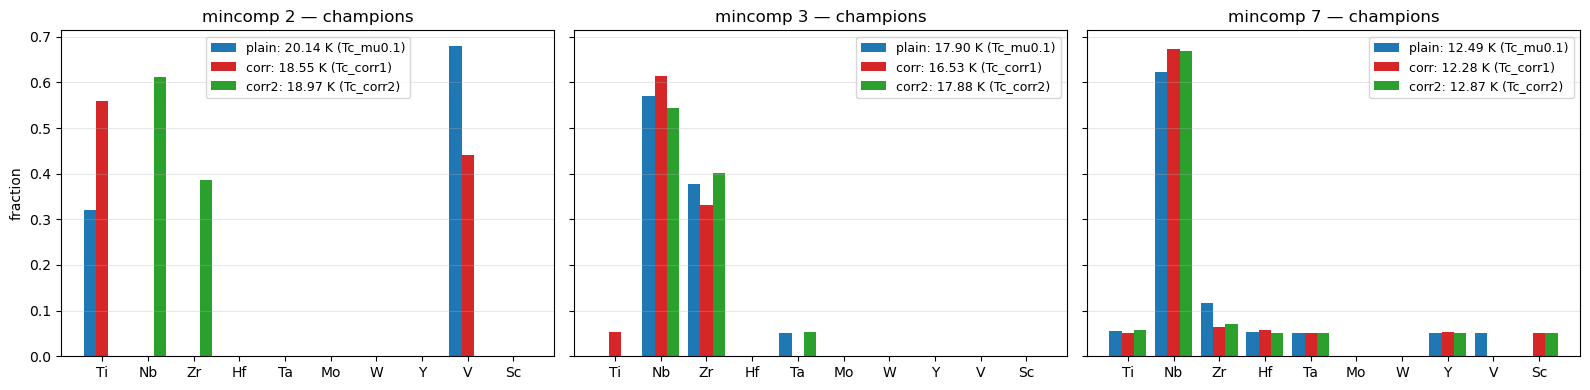

In [5]:
fig, axes = plt.subplots(1, len(MCS), figsize=(16, 4), sharey=True)
w = 0.27
x = np.arange(len(ELEMENTS))
for a, mc in zip(axes, MCS):
    for k, var in enumerate(VARS):
        b = champion(RUNS[var, mc])
        a.bar(x + (k - 1) * w, vec(b), w, label=f"{var}: {b['Tc']:.2f} K ({TGT[var]})", color=VAR_COL[var])
    a.set_xticks(x); a.set_xticklabels(ELEMENTS); a.set_title(f'mincomp {mc} — champions'); a.grid(alpha=.3, axis='y')
    a.legend(fontsize=9)
axes[0].set_ylabel('fraction')
plt.tight_layout(); plt.show()

## 3. Top-5 distinct valid compositions of each run

In [6]:
def top_distinct(r, n=5, mind=0.03):
    v = r['df'][r['df'].valid].sort_values('Tc', ascending=False)
    picked = []
    for _, row in v.iterrows():
        if all(np.linalg.norm(vec(row) - vec(p)) > mind for p in picked):
            picked.append(row)
        if len(picked) == n:
            break
    return pd.DataFrame([{'run': r['label'], 'rank': i + 1, 'comp': p.comp, 'iter': int(p.iteration),
                          **{m: p[m] for m in METRICS}, 'λ_es2': p.lam_es2}
                         for i, p in enumerate(picked)])

TOP = pd.concat([top_distinct(RUNS[var, mc]) for mc in MCS for var in VARS]).set_index(['run', 'rank'])
TOP.style.format({**{m: '{:.2f}' for m in METRICS}, 'λ_es2': '{:.3f}'}, na_rep='—')

## 4. Convergence — best-so-far (valid) champion of each run, evaluated in all three metrics

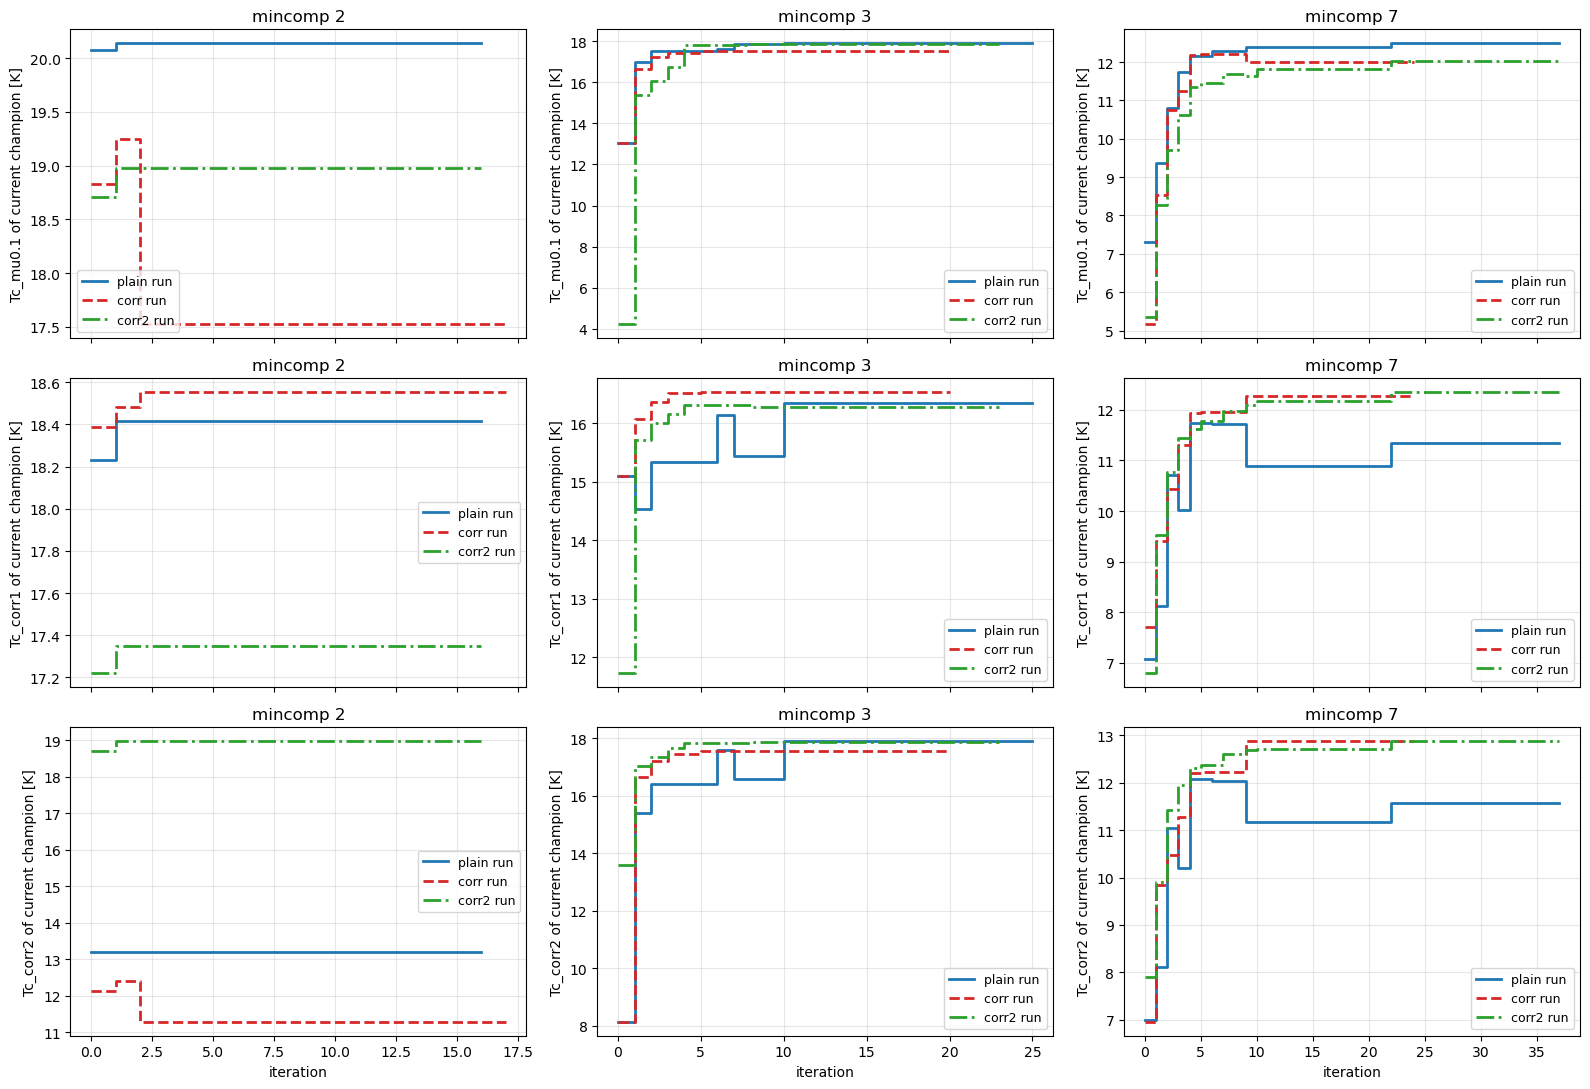

In [7]:
fig, axes = plt.subplots(len(METRICS), len(MCS), figsize=(16, 11), sharex='col')
for j, mc in enumerate(MCS):
    for var in VARS:
        r = RUNS[var, mc]; v = r['df'][r['df'].valid]
        its = np.arange(0, r['n_iter'] + 1)
        best_idx = [v[v.iteration <= k].Tc.idxmax() for k in its]   # the run's own champion trajectory
        for i, metric in enumerate(METRICS):
            axes[i, j].step(its, v.loc[best_idx, metric].values, where='post', color=VAR_COL[var],
                            ls=VAR_LS[var], lw=2, label=f'{var} run')
    for i, metric in enumerate(METRICS):
        axes[i, j].set(ylabel=f'{metric} of current champion [K]', title=f'mincomp {mc}')
        axes[i, j].grid(alpha=.3); axes[i, j].legend(fontsize=9)
    axes[-1, j].set_xlabel('iteration')
plt.tight_layout(); plt.show()

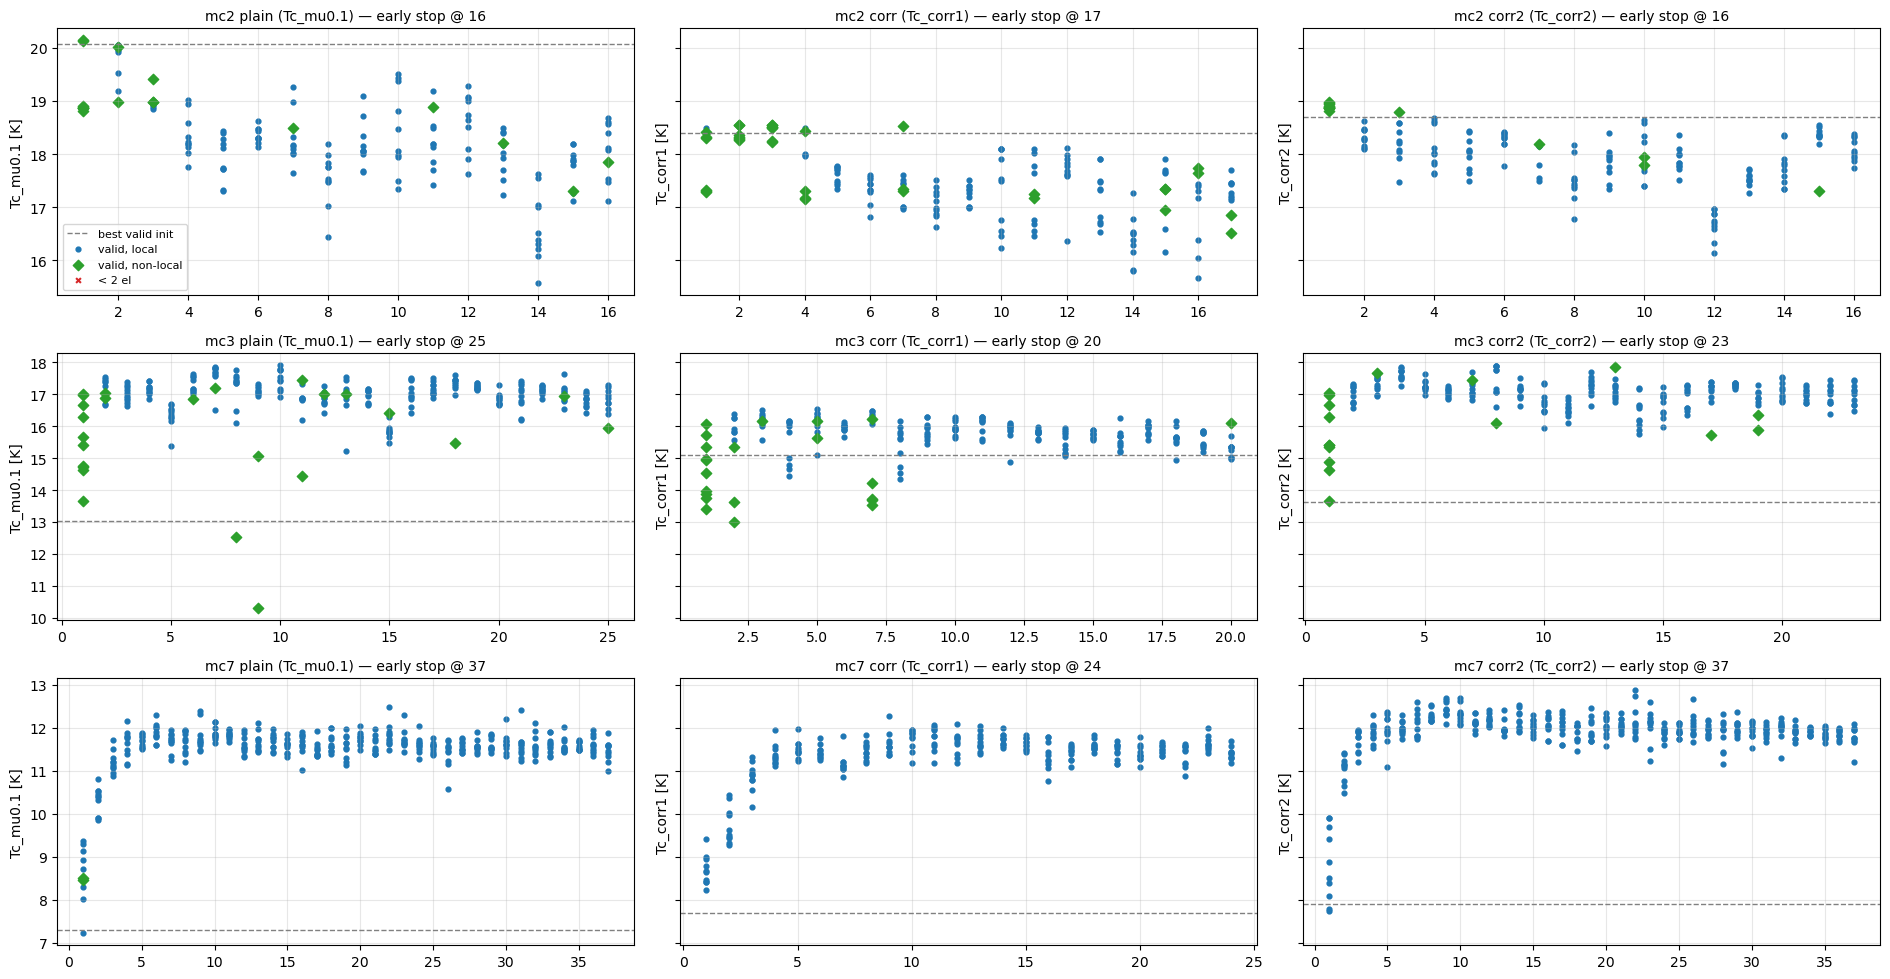

In [8]:
fig, axes = plt.subplots(len(MCS), len(VARS), figsize=(19, 3.3 * len(MCS)), sharey='row', squeeze=False)
for i, mc in enumerate(MCS):
    for j, var in enumerate(VARS):
        r = RUNS[var, mc]; d = r['df']; io = d[d.iteration > 0]; a = axes[i, j]
        a.axhline(d[(d.iteration == 0) & d.valid].Tc.max(), color='gray', ls='--', lw=1, label='best valid init')
        loc = io.source == 'local'
        a.scatter(io[io.valid & loc].iteration, io[io.valid & loc].Tc, s=12, c='C0', label='valid, local')
        a.scatter(io[io.valid & ~loc].iteration, io[io.valid & ~loc].Tc, s=28, c='C2', marker='D', label='valid, non-local')
        a.scatter(io[~io.valid].iteration, io[~io.valid].Tc, s=12, c='C3', marker='x', label=f'< {mc} el')
        a.set_title(f"{r['label']} ({r['target']}) — {r['status']}", fontsize=10); a.grid(alpha=.3)
        a.set_ylabel(f"{r['target']} [K]")
axes[0, 0].legend(fontsize=8)
plt.tight_layout(); plt.show()

## 5. Composition of the evaluated batches — mean element fraction per iteration

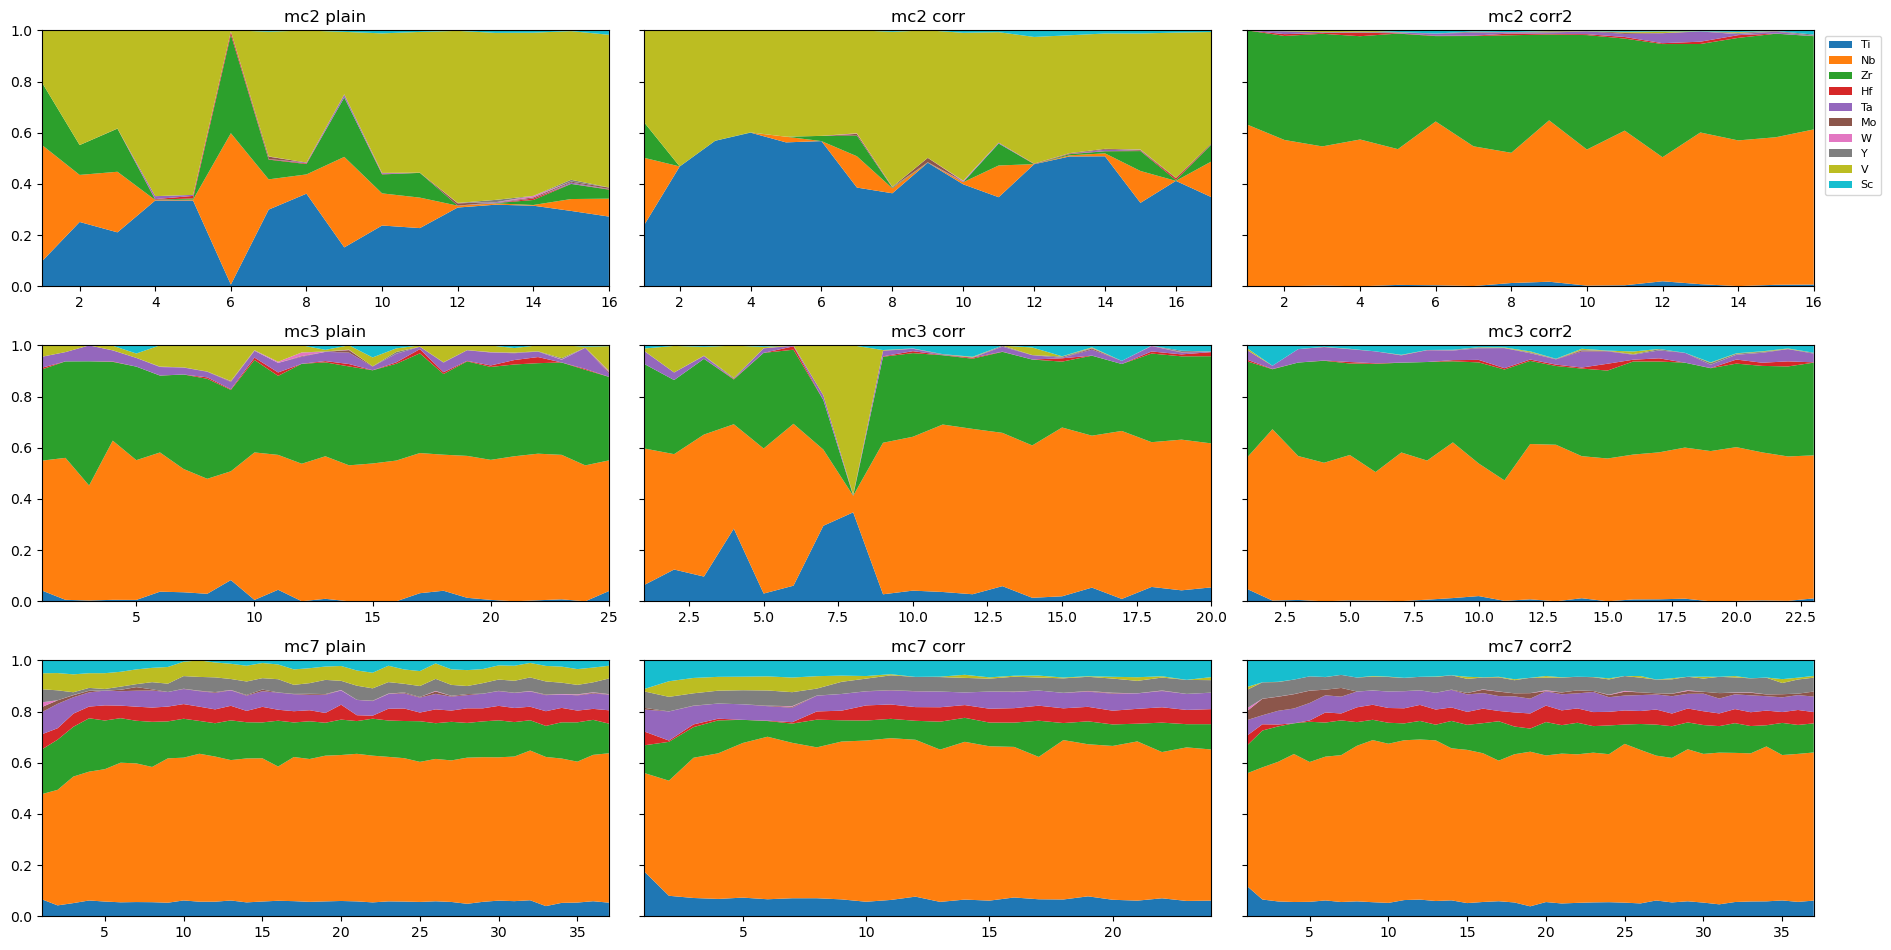

In [9]:
fig, axes = plt.subplots(len(MCS), len(VARS), figsize=(19, 3.2 * len(MCS)), sharey=True, squeeze=False)
for i, mc in enumerate(MCS):
    for j, var in enumerate(VARS):
        r = RUNS[var, mc]; io = r['df'][r['df'].iteration > 0]
        m = io.groupby('iteration')[ELEMENTS].mean()
        axes[i, j].stackplot(m.index, m.T.values, labels=ELEMENTS, colors=[EL_COLORS[e] for e in ELEMENTS])
        axes[i, j].set(title=r['label'], xlim=(m.index.min(), m.index.max()), ylim=(0, 1))
axes[0, -1].legend(loc='upper left', bbox_to_anchor=(1.01, 1), fontsize=8)
plt.tight_layout(); plt.show()

## 6. `Tc_corr1` and `Tc_corr2` vs `Tc_mu0.1` of all evaluated points

Init points in grey; points selected by plain runs in blue, by corr runs in red, by corr2 runs in green. Above the
diagonal the correction raises Tc (Sc-rich, and Ti-rich in corr1: lower θ_D → higher λ), below it lowers Tc
(V-rich: λ_es). In `Tc_corr2` everything without V and Sc lies exactly on the diagonal.

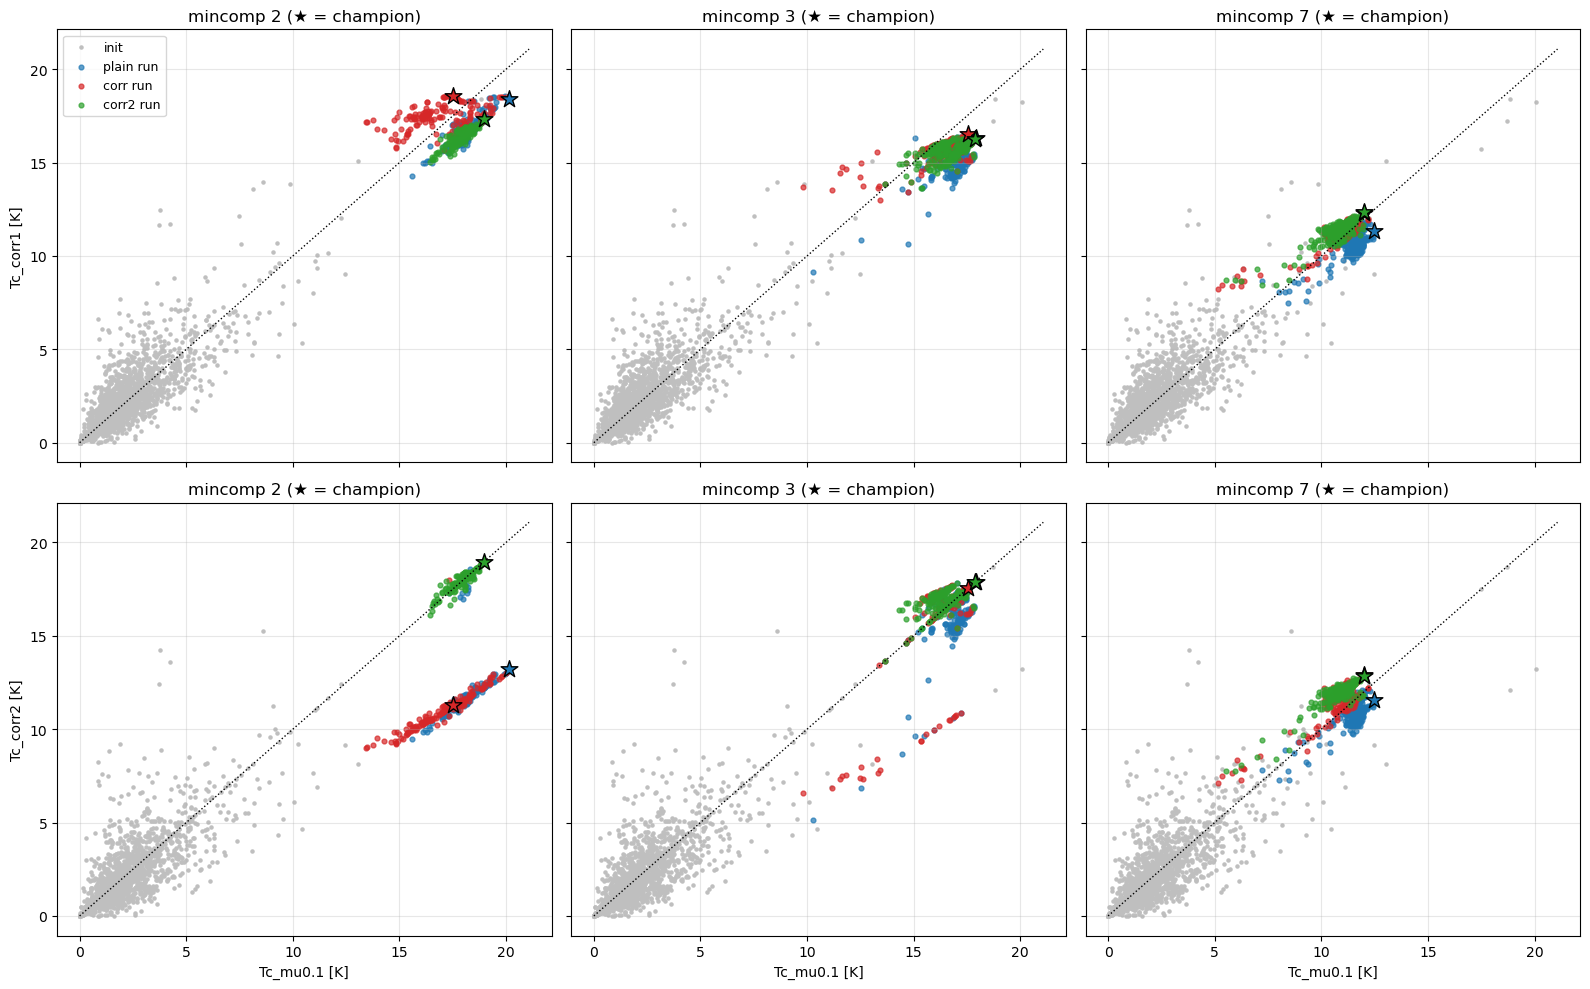

In [10]:
fig, axes = plt.subplots(2, len(MCS), figsize=(16, 10), sharex=True, sharey=True)
lim = [0, INIT[METRICS].max().max() + 1]
for i, metric in enumerate(('Tc_corr1', 'Tc_corr2')):
    for a, mc in zip(axes[i], MCS):
        a.scatter(INIT['Tc_mu0.1'], INIT[metric], s=5, c='0.75', label='init')
        for var in VARS:
            io = RUNS[var, mc]['df']; io = io[io.iteration > 0]
            a.scatter(io['Tc_mu0.1'], io[metric], s=12, c=VAR_COL[var], alpha=.7, label=f'{var} run')
            b = champion(RUNS[var, mc])
            a.scatter(b['Tc_mu0.1'], b[metric], s=160, marker='*', c=VAR_COL[var], edgecolor='k', zorder=5)
        a.plot(lim, lim, 'k:', lw=1)
        a.set(title=f'mincomp {mc} (★ = champion)'); a.grid(alpha=.3)
    axes[i, 0].set_ylabel(f'{metric} [K]')
for a in axes[-1]:
    a.set_xlabel('Tc_mu0.1 [K]')
axes[0, 0].legend(fontsize=9)
plt.tight_layout(); plt.show()

## 7. Element content of the champions vs mincomp

In [11]:
rows = []
for (var, mc), r in RUNS.items():
    b = champion(r)
    rows.append({'mincomp': mc, 'variant': var, **{el: 100 * b[el] for el in ELEMENTS}})
EL = pd.DataFrame(rows).set_index(['mincomp', 'variant'])
EL.style.format('{:.0f}').background_gradient(axis=None, cmap='Blues')

## 8. Surrogate quality — CatBoost prediction at selection vs KKR value of the run's target

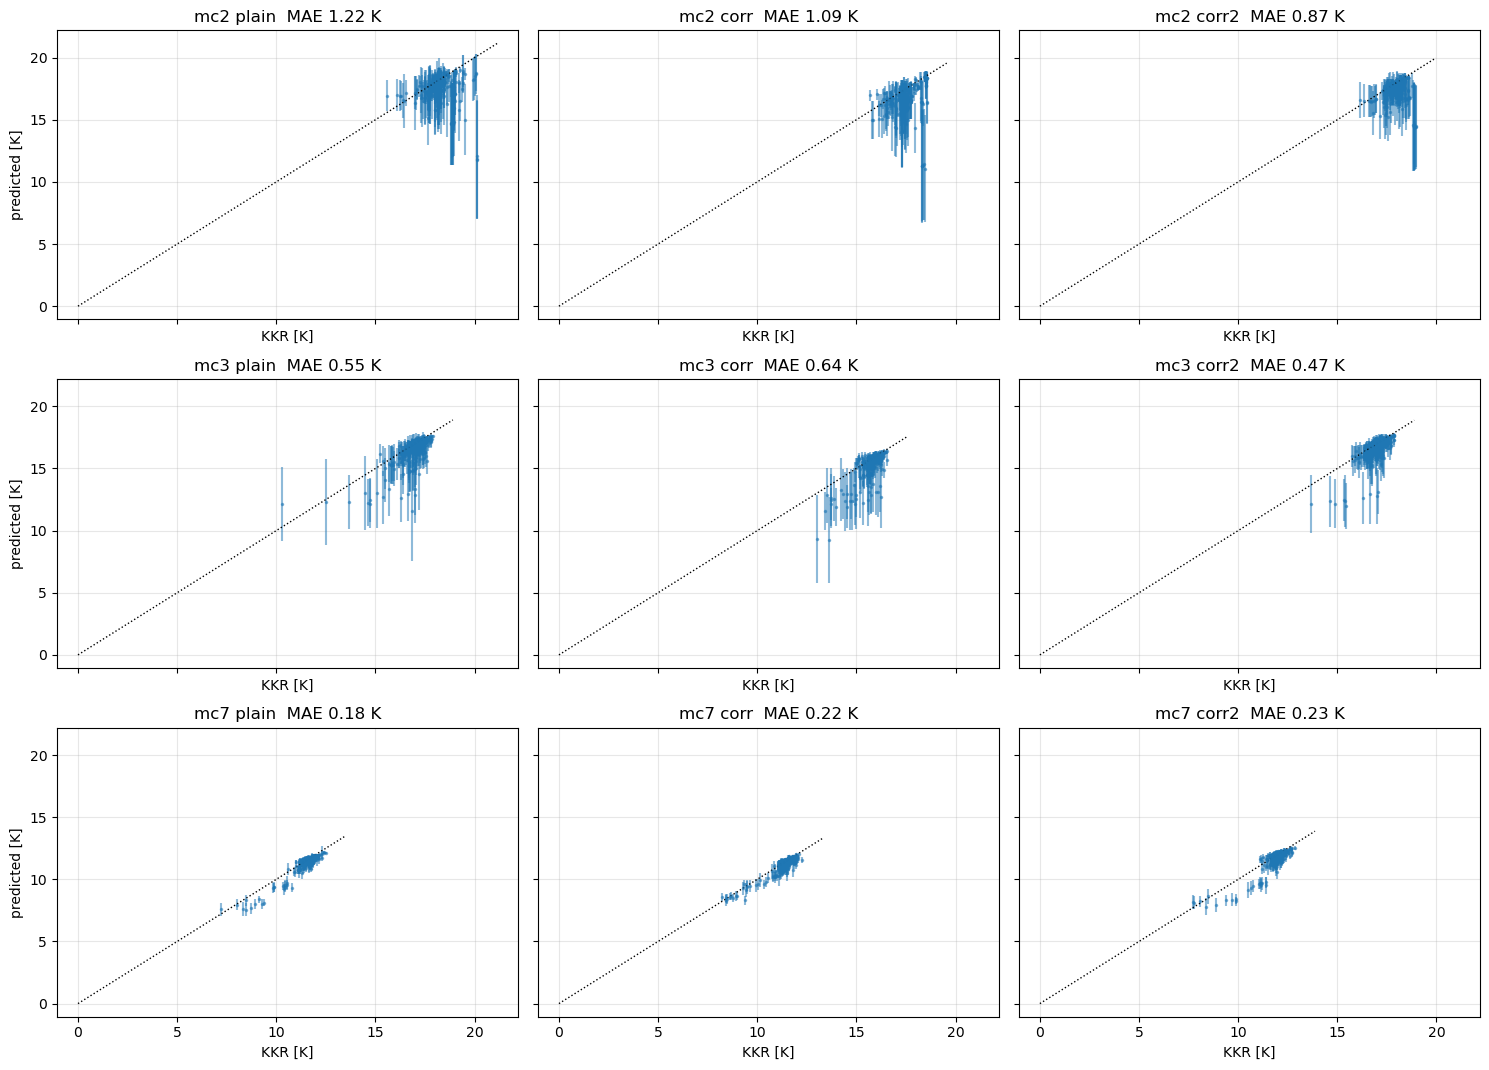

In [12]:
fig, axes = plt.subplots(len(MCS), len(VARS), figsize=(15, 3.6 * len(MCS)), sharex=True, sharey=True)
for a, r in zip(axes.ravel(), RUNS.values()):
    io = r['df'][(r['df'].iteration > 0) & r['df'].pred.notna()]
    a.errorbar(io.Tc, io.pred, yerr=io.pred_std, fmt='.', ms=3, alpha=.5)
    mae = (io.pred - io.Tc).abs().mean()
    lim = [0, max(io.Tc.max(), io.pred.max()) + 1]
    a.plot(lim, lim, 'k:', lw=1)
    a.set(title=f"{r['label']}  MAE {mae:.2f} K", xlabel='KKR [K]'); a.grid(alpha=.3)
for a in axes[:, 0]:
    a.set_ylabel('predicted [K]')
plt.tight_layout(); plt.show()

## 9. Conclusions

All 9 runs early-stopped (plain 16/25/37 iterations, corr 17/20/24, corr2 16/23/37 for mc 2/3/7); every new point
satisfied mincomp; the search is local (79–100 % of points from the top-K neighbourhood).

**mincomp 2 — corr2 moves the binary champion from V–Ti to Nb–Zr.** plain and corr end on the V–Ti edge
(V68Ti32 20.14 K in Tc_mu0.1; Ti56V44 18.55 K in Tc_corr1). corr2 ends on Nb61Zr39, 18.97 K, which is the set-A
champion; with no V and Sc, Tc_corr2 = Tc_mu0.1 for it. Its top 5 are all Nb–Zr (Nb53–68). In Tc_corr2 the V–Ti
edge drops to ≈ 11–13 K (V68Ti32 13.20 K, Ti56V44 11.29 K, λ_es ≈ 0.08), i.e. below Nb–Zr by ≈ 6 K, with a ranking
Nb–Zr > Ti–V that the earlier versions did not give. The Nb–Zr edge was already in the init database
(Nb68Zr32 18.70 K); the run refines it by +0.27 K.

**mincomp 3 — Nb–Zr + 5 % third element in all three.** plain Nb57Zr38Ta5 (17.90 K), corr Nb61Zr33Ti5 (16.53 K),
corr2 Nb54Zr40Ta5 (17.88 K). corr2 and plain champions are 0.04 apart and both contain no V/Sc, so they have the
same Tc in both metrics. The V-containing plain candidates (Nb57Zr38V5 17.85 K) lose ≈ 1.25 K in Tc_corr2. Sc as
the third element is near-optimal in corr2 (Nb63Zr32Sc5 17.85 K).

**mincomp 7 — the same Nb-rich basin, filler Sc instead of V.** corr2 Nb67Zr7Ti6Ta5Y5Hf5Sc5 (12.87 K) is almost
the corr champion (distance 0.01); plain Nb62Zr12Ti6Hf5Ta5Y5V5 (12.49 K) is 0.10 away. Under Tc_corr2 the plain
champion drops to 11.58 K (V: λ_es), the corr2 champion is 12.02 K in Tc_mu0.1. corr2 top 5 all contain 5–8 % Sc and
no V.

**Summary.** With the revised correction (Sc bcc θ_D + λ_es on V only) the optimiser leaves V–Ti in the binary limit
and goes to Nb–Zr in every mincomp. For mc ≥ 3 it reproduces the plain/corr basin (Nb–Zr-rich, Tc within ≈ 1 K);
the only systematic difference is the minor element: Sc in place of V.